# `golftrainer` 1.0.2 benchmark

The published package is much smaller than its description suggests. The wheel contains only dataclasses, a JSON factory, and coordinate-to-DataFrame conversion. It contains **no analysis metrics, phase detector, geometry module, plots, scoring, thresholds, or coaching interpretations**. Repository-only modules must not be mistaken for installed 1.0.2 functionality.

In [1]:
from pathlib import Path
from collections import Counter
import inspect, json, platform, subprocess
import importlib.metadata as md
import matplotlib.pyplot as plt, numpy as np, pandas as pd
from IPython.display import display

ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SAMPLES=ROOT/"data"/"raw"/"golftracker_samples"
OUT=ROOT/"outputs"/"golftrainer"; OUT.mkdir(parents=True,exist_ok=True)

import golftrainer
from golftrainer import factory, golf_data

display(pd.DataFrame({"value":{
    "Python":platform.python_version(), "golftrainer":md.version("golftrainer"),
    "pandas":pd.__version__, "NumPy":np.__version__,
    "MediaPipe":"not a dependency", "OpenCV":"not a dependency",
}}))
print("import path:",inspect.getfile(golftrainer))
print("requirements:",md.requires("golftrainer"))

,value
Python,3.11.18
golftrainer,1.0.2
pandas,3.1.0
NumPy,2.4.6
MediaPipe,not a dependency
OpenCV,not a dependency


import path: /home/tsispace/Documents/GitHub/golf-balance/envs/golftrainer/lib/python3.11/site-packages/golftrainer/__init__.py
requirements: ['pandas', 'numpy', "pytest >=3.7 ; extra == 'dev'", "check-manifest ; extra == 'dev'", "twine ; extra == 'dev'"]


## Installed source and CLI

The wheel contains `__init__.py`, `__version__.py`, `factory.py`, and `golf_data.py`. The advertised `golf_trainer` wrapper targets an omitted `scripts.golf_trainer`, so it fails. Public `GolfData` methods only name columns and return normalized, screen-origin, or Cartesian-origin DataFrames.

In [2]:
package_dir=Path(inspect.getfile(golftrainer)).parent
rows=[]
for p in sorted(package_dir.glob("*.py")):
    rows.append({"file":p.name,"lines":len(p.read_text().splitlines()),"functions/classes":[n for n,v in inspect.getmembers(__import__(f"golftrainer.{p.stem}",fromlist=[p.stem])) if inspect.isfunction(v) or inspect.isclass(v)]})
display(pd.DataFrame(rows))
print("GolfData methods:",[n for n,v in inspect.getmembers(golf_data.GolfData,inspect.isfunction) if not n.startswith("__")])

cli=ROOT/"envs"/"golftrainer"/"bin"/"golf_trainer"
probe=subprocess.run([str(cli),"--help"],text=True,capture_output=True)
print("CLI return code:",probe.returncode); print(probe.stderr)

,file,lines,functions/classes
0,__init__.py,0,[]
1,__version__.py,1,[]
2,factory.py,27,"[create_golf_data, create_golf_data_s]"
3,golf_data.py,115,"[ClubHeadResult, GolfData, MpResult, PoseResul..."


GolfData methods: ['cart_data_frame', 'col_names', 'mp_4d_names', 'mp_data_frame', 'norm_data_frame', 'screen_data_frame']
CLI return code: 1
Traceback (most recent call last):
  File "/home/tsispace/Documents/GitHub/golf-balance/envs/golftrainer/bin/golf_trainer", line 3, in <module>
    from scripts.golf_trainer import main
ModuleNotFoundError: No module named 'scripts'



## Expected JSON schema and real compatibility

The factory requires these exact fields:

- `version`
- `video_spec`: height, width, num_frames, fps, scale, rotate
- `video_input`: fname, size
- `num_frames`
- `pose_result`: poses, handed
- `club_head_result`: norm_points, algos
- `mp_result`: landmarks, norm_points

Only supplied `00001.json` satisfies it. The other supplied exports and a fresh `golftracker` 2.0 export fail at `version` before their deeper `mp_result` incompatibility is reached.

In [3]:
def shape_tree(obj):
    if isinstance(obj,dict): return {k:shape_tree(v) for k,v in obj.items()}
    if isinstance(obj,list): return f"list[{len(obj)}]" + (f" of {shape_tree(obj[0])}" if obj else "")
    return type(obj).__name__

payload=json.loads((SAMPLES/"00001.json").read_text())
display(shape_tree(payload))
gd=factory.create_golf_data(str(SAMPLES/"00001.json"))
print(gd)

failures=[]
for name in ["00002.json","00003.json","00004.json"]:
    try: factory.create_golf_data(str(SAMPLES/name))
    except Exception as exc: failures.append((name,type(exc).__name__,str(exc)))
display(pd.DataFrame(failures,columns=["input","error","message"]))

{'version': 'float',
 'video_spec': {'height': 'int',
  'width': 'int',
  'num_frames': 'int',
  'fps': 'int',
  'scale': 'int',
  'rotate': 'str'},
 'video_input': {'fname': 'str', 'size': 'int'},
 'num_frames': 'int',
 'pose_result': {'poses': 'list[136] of str', 'handed': 'str'},
 'club_head_result': {'norm_points': 'list[136] of list[2] of float',
  'algos': 'list[136] of str'},
 'mp_result': {'landmarks': 'list[33] of str',
  'norm_points': 'list[136] of list[132] of float'}}

GolfData(version=1.0, video_spec=VideoSpec(height=768, width=432, num_frames=136, fps=30, scale=100, rotate=''), video_input=VideoInput(fname='00001.mov', size=1557075), num_frames=136, pose_result=PoseResult(poses=['RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'Unknown', 'RhStart', 'Unknown', 'RhStart', 'Unknown', 'RhStart', 'RhStart', 'RhStart', 'Unknown', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'RhStart', 'Unknown', 'Unknown', 'RhStart', 'RhStart', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Unknown', 'Un

,input,error,message
0,00002.json,KeyError,'version'
1,00003.json,KeyError,'version'
2,00004.json,KeyError,'version'


## Outputs actually generated by 1.0.2

`mp_data_frame()` returns 132 columns: all 33 MediaPipe landmarks times `(x,y,z,visibility)`. `norm_data_frame()` keeps pose `(x,y)` and appends club-head `(x,y)`, replacing missing club points with `(0,0)`. `screen_data_frame()` scales normalized points to top-left-origin pixels; `cart_data_frame()` also flips `y` to bottom-left origin.

There are no packaged formulas for tempo, angles, swing phases, key positions, or coaching scores. Stored pose labels and `club_source` values are inputs passed through from golftracker, not golftrainer-derived features.

In [4]:
mp=gd.mp_data_frame(); norm=gd.norm_data_frame(); screen=gd.screen_data_frame(); cart=gd.cart_data_frame()
print("mp",mp.shape,"norm",norm.shape,"screen",screen.shape,"cart",cart.shape)
display(norm.head())
display(pd.DataFrame({"pose":Counter(gd.pose_result.poses),"club source":Counter(gd.club_head_result.algos)}).fillna(0).astype(int))
norm.assign(frame=np.arange(len(norm)),timestamp=np.arange(len(norm))/gd.video_spec.fps).to_csv(OUT/"00001_golftrainer_table.csv",index=False)

mp (136, 132) norm (136, 68) screen (136, 68) cart (136, 68)


,nose_x,nose_y,left_eye_inner_x,left_eye_inner_y,left_eye_x,left_eye_y,left_eye_outer_x,left_eye_outer_y,right_eye_inner_x,right_eye_inner_y,...,left_heel_x,left_heel_y,right_heel_x,right_heel_y,left_foot_index_x,left_foot_index_y,right_foot_index_x,right_foot_index_y,club_head_x,club_head_y
0,0.458343,0.366363,0.458418,0.357091,0.455306,0.356113,0.452104,0.355044,0.464443,0.358668,...,0.299297,0.718293,0.299833,0.738713,0.397357,0.714871,0.412164,0.731642,0.75,0.736979
1,0.456569,0.367213,0.457148,0.357273,0.454255,0.356206,0.451422,0.355091,0.463206,0.358702,...,0.296591,0.717631,0.295484,0.737799,0.393212,0.713968,0.410050,0.733461,0.75,0.736979
2,0.458137,0.366164,0.459238,0.356296,0.456529,0.355370,0.453914,0.354447,0.464644,0.357778,...,0.299572,0.715079,0.294931,0.738135,0.395618,0.712842,0.410940,0.733196,0.75,0.736979
3,0.456468,0.366068,0.456722,0.356192,0.453387,0.354976,0.450069,0.353740,0.464116,0.358177,...,0.296925,0.719203,0.298545,0.733977,0.393913,0.715769,0.411976,0.732277,0.75,0.736979
4,0.463796,0.365313,0.463465,0.355917,0.461039,0.355131,0.458652,0.354334,0.467639,0.357176,...,0.303399,0.716676,0.301299,0.734396,0.407276,0.717894,0.419416,0.732882,0.75,0.736979


,pose,club source
RhStart,54,0
Unknown,57,0
RhTop,13,0
RhFinish,12,0
Label,0,24
LinearFit,0,72
Invalid,0,40


## Independent diagnostics from package-exposed coordinates

The plots below are our diagnostics over `GolfData` tables, not metrics claimed by golftrainer. They demonstrate that its useful reusable component is coordinate/schema access. No new pose estimator is run.

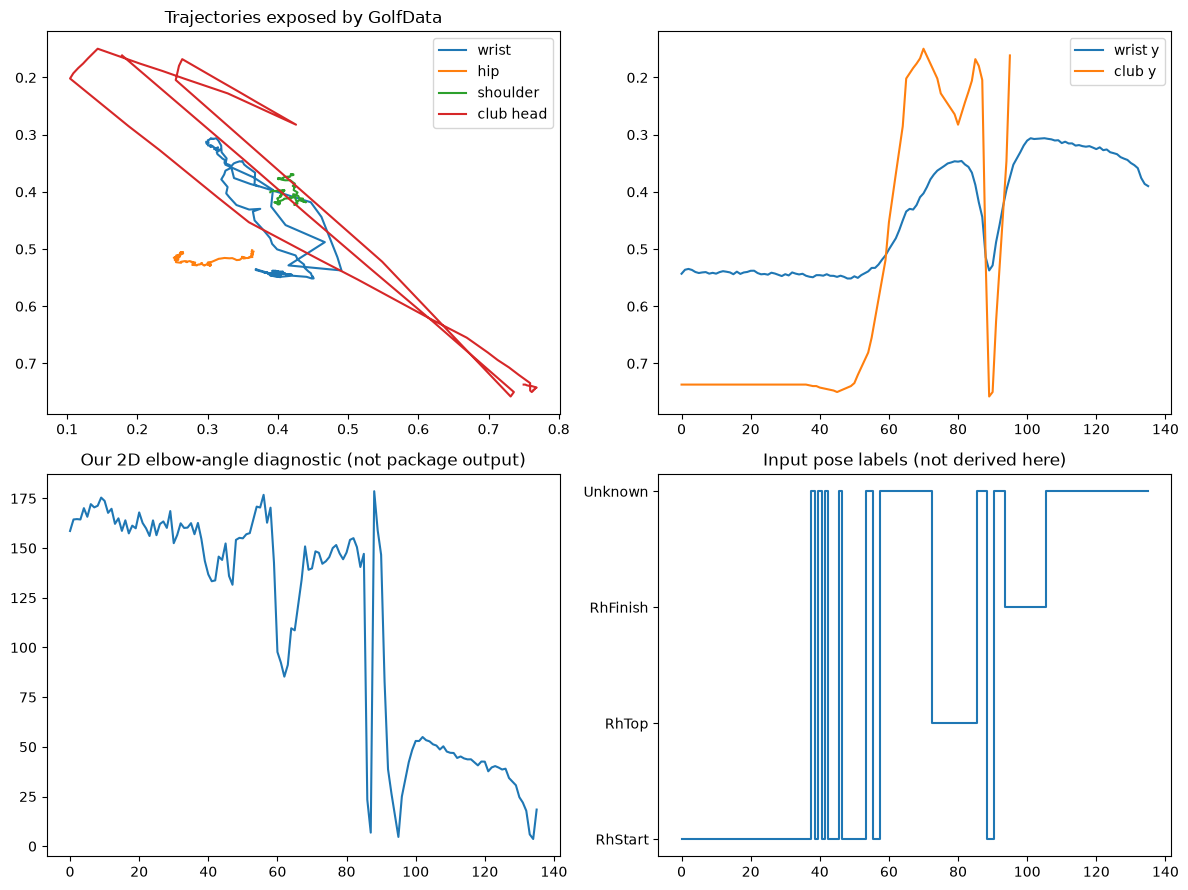

In [5]:
df=norm.copy(); df["frame"]=np.arange(len(df)); df["timestamp"]=df.frame/gd.video_spec.fps
for part in ["wrist","hip","shoulder"]:
    df[f"{part}_x"]=df[[f"left_{part}_x",f"right_{part}_x"]].mean(axis=1)
    df[f"{part}_y"]=df[[f"left_{part}_y",f"right_{part}_y"]].mean(axis=1)

def joint_angle(ax,ay,bx,by,cx,cy):
    a=np.column_stack([ax-bx,ay-by]); c=np.column_stack([cx-bx,cy-by])
    den=np.linalg.norm(a,axis=1)*np.linalg.norm(c,axis=1)
    cosine=np.divide((a*c).sum(axis=1),den,out=np.full(len(den),np.nan),where=den!=0)
    return np.degrees(np.arccos(np.clip(cosine,-1,1)))

df["left_elbow_angle_diag"]=joint_angle(df.left_shoulder_x,df.left_shoulder_y,df.left_elbow_x,df.left_elbow_y,df.left_wrist_x,df.left_wrist_y)
fig,axes=plt.subplots(2,2,figsize=(12,9))
for part in ["wrist","hip","shoulder"]: axes[0,0].plot(df[f"{part}_x"],df[f"{part}_y"],label=part)
axes[0,0].plot(df.club_head_x.replace(0,np.nan),df.club_head_y.replace(0,np.nan),label="club head")
axes[0,0].invert_yaxis(); axes[0,0].legend(); axes[0,0].set_title("Trajectories exposed by GolfData")
axes[0,1].plot(df.frame,df.wrist_y,label="wrist y"); axes[0,1].plot(df.frame,df.club_head_y.replace(0,np.nan),label="club y"); axes[0,1].invert_yaxis(); axes[0,1].legend()
axes[1,0].plot(df.frame,df.left_elbow_angle_diag); axes[1,0].set_title("Our 2D elbow-angle diagnostic (not package output)")
phase_codes=pd.Categorical(gd.pose_result.poses,categories=["RhStart","RhTop","RhFinish","Unknown"]).codes
axes[1,1].step(df.frame,phase_codes,where="mid"); axes[1,1].set_yticks(range(4),["RhStart","RhTop","RhFinish","Unknown"]); axes[1,1].set_title("Input pose labels (not derived here)")
fig.tight_layout(); fig.savefig(OUT/"00001_golftrainer_diagnostics.png",dpi=140)
plt.show()

## Reuse assessment

The installed feature calculations can be reused independently because there effectively are no calculations beyond table conversion. The dataclass/factory idea is useful, and the raw coordinates are valuable, but the schema needs versioning, validation, nullable values instead of `(0,0)`, timestamps/frame IDs, compatibility tests with the producer, and actual analysis modules.

Repository source after the PyPI release contains experimental `geom.py`, `plot_utils.py`, and `swing_analysis.py`, including club-direction threshold phase segmentation and a nearest-return impact heuristic. Those files are not in wheel 1.0.2 and should not be credited as installed functionality; the phase code is also fragile and includes indexing/phase-range defects.

In [6]:
print("EXECUTED_OK: golftrainer notebook reached the final cell")

EXECUTED_OK: golftrainer notebook reached the final cell
